# From a p-value to a decision: the margin, the interval, and the word it buys

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/firefly1248/demo-notebooks/blob/main/notebooks/model_comparison_decision.ipynb)

Two configurations of one model, scored on many datasets, one paired difference per dataset. A
p-value answers whether that difference is distinguishable from zero. It does not answer the question
that the comparison was run for, which is whether to ship the change, and those two come apart in
both directions: a difference too small to matter can be highly significant, and a difference that
would matter can fail to reach significance because there are not enough datasets to see it.

This notebook turns the same numbers into a decision. It fixes a margin first, reads the paired
difference against it, and returns one of three words. Along the way it shows how little it takes to
move the verdict: the quantity the test runs on, the number of datasets, the margin itself, and
whether datasets that are variants of one problem are counted once or several times.

The data is one row per dataset from a small-data benchmark: CatBoost tuned from a uniform start
against the same model re-tuned from the class prior.

In [1]:
import numpy as np, pandas as pd
from scipy import stats

pd.set_option("display.width", 200, "display.max_columns", 30)

# the published table of the benchmark, pinned to a commit so the numbers here do not drift
BENCHMARK = "https://raw.githubusercontent.com/firefly1248/SmallDataBenchmarks/0227b621e4cfbd4eed32797b9054484defed794f/"
D = pd.read_csv(BENCHMARK + "results/catboost_retune_calibration.csv")
BAL = D[D.group == "balanced"]
NDATA = len(D)
print(f"{NDATA} datasets, {len(BAL)} of them balanced, one row each")
print(D.columns.tolist())

108 datasets, 30 of them balanced, one row each
['dataset', 'group', 'Brier uniform', 'ECE uniform', 'gap uniform', 'PR AUC uniform', 'Brier prior retuned', 'ECE prior retuned', 'gap prior retuned', 'PR AUC prior retuned', 'Brier prior fixed', 'ECE prior fixed', 'gap prior fixed', 'PR AUC prior fixed']


## First, which quantity

The calibration column is a signed confidence gap: a model that is too confident lands on one side of
zero, one that is too cautious on the other. Averaging it lets the two cancel. What a calibration
claim is about is the size of the miss, which is the absolute gap, and that is a different column of
numbers with a different test attached to it.

The cell below runs the same test on both, on the balanced datasets and on all of them. Nothing about
the data changes between the two columns, only the quantity.

In [2]:
# the bars in a metric's name are its transform: "|gap|" is the absolute gap, "PR AUC" is as it comes
def difference(frame, metric):
    col = metric.strip("|")
    a, b = frame[f"{col} uniform"], frame[f"{col} prior retuned"]
    return (b.abs() - a.abs()) if metric.startswith("|") else b - a      # re-tuned minus uniform


print("Wilcoxon on the paired differences, re-tuned against the uniform start")
for name, frame in (("the balanced ones", BAL), ("every dataset", D)):
    print(f"  {name:18s} n={len(frame):3d}  "
          f"signed gap p={stats.wilcoxon(difference(frame, 'gap')).pvalue:.3g}   "
          f"absolute gap p={stats.wilcoxon(difference(frame, '|gap|')).pvalue:.3g}")

Wilcoxon on the paired differences, re-tuned against the uniform start
  the balanced ones  n= 30  signed gap p=0.015   absolute gap p=0.144
  every dataset      n=108  signed gap p=1.81e-07   absolute gap p=0.000382


## The margin, and the rule that reads it

A difference smaller than some margin changes nothing for whoever uses the model, and the margin comes
from that use, not from the data. It has to be written down before the interval is computed, because a
margin chosen after seeing the interval is a margin chosen to reach a verdict.

With a margin in hand the reading is mechanical. A 90% interval wholly inside the band is equivalence,
which is Schuirmann's two one-sided tests at the 5% level; an interval wholly past one end is a
verdict in that direction; an interval straddling an end is unclear, and unclear is a result, not a
failure.

Which end counts as a win is not a property of the interval but of the metric, so the direction is
carried alongside the margin here rather than assumed.

In [3]:
SPEC = {"PR AUC": (0.005, 1), "|gap|": (0.01, -1)}    # the margin, set before the run, and which
RNG_SEED = 0                                          # end of the band is the win for that metric


def t90(x):
    h = stats.t.ppf(0.95, len(x) - 1)*x.std(ddof=1)/np.sqrt(len(x))
    return x.mean() - h, x.mean() + h


def boot90(x, n_boot=20_000):                    # seeded per call, so re-running a cell repeats it
    m = np.random.default_rng(RNG_SEED).choice(x.to_numpy(), (n_boot, len(x))).mean(axis=1)
    return tuple(np.percentile(m, [5, 95]))


def verdict(lo, hi, margin, sign):
    if sign < 0:                                 # orient once, so one comparison serves both metrics
        lo, hi = -hi, -lo
    if -margin < lo and hi < margin:
        return "equivalent"
    return "better" if lo > margin else "worse" if hi < -margin else "unclear"

## The same pair, four verdicts

Four readings of one comparison: the accuracy metric and the calibration metric, each on all the
datasets and on a smaller slice of them. The t interval and the bootstrap interval are both shown,
because an interval that decides something should not depend on which of the two was used.

In [4]:
SUB = D.sample(15, random_state=0)
ROWS = [("PR AUC", "every dataset", D), ("PR AUC", "one random draw", SUB),
        ("|gap|", "every dataset", D), ("|gap|", "the balanced ones", BAL)]


def reading(metric, rows, frame):
    margin, sign = SPEC[metric]
    x = difference(frame, metric)
    lo, hi = t90(x)
    blo, bhi = boot90(x)
    return {"metric": metric, "rows": rows, "n": len(x), "margin": margin, "mean": x.mean(),
            "median": x.median(), "lo": lo, "hi": hi, "boot lo": blo, "boot hi": bhi,
            "in margins": f"[{lo/margin:+.2f}, {hi/margin:+.2f}]",
            "wilcoxon n": int((x != 0).sum()),       # scipy drops the exact zeros before ranking
            "wilcoxon p": stats.wilcoxon(x).pvalue, "verdict": verdict(lo, hi, margin, sign)}


TAB = pd.DataFrame([reading(*r) for r in ROWS])
print(TAB.drop(columns="margin").round(4).to_string(index=False))

metric              rows   n    mean  median      lo      hi  boot lo  boot hi     in margins  wilcoxon n  wilcoxon p    verdict
PR AUC     every dataset 108 -0.0003 -0.0001 -0.0024  0.0017  -0.0023   0.0017 [-0.48, +0.35]         102      0.3126 equivalent
PR AUC   one random draw  15 -0.0007 -0.0001 -0.0101  0.0088  -0.0089   0.0083 [-2.02, +1.76]          14      0.8261    unclear
 |gap|     every dataset 108 -0.0197 -0.0038 -0.0283 -0.0111  -0.0284  -0.0115 [-2.83, -1.11]         107      0.0004     better
 |gap| the balanced ones  30 -0.0144 -0.0016 -0.0290  0.0002  -0.0291  -0.0014 [-2.90, +0.02]          29      0.1444    unclear


## How much of that is the number of datasets

The second row above is one draw of fifteen. Drawing many of them, with the metric and the margin
held fixed, separates what the evidence says from what the size of the comparison says.

There are two versions of that question and the cell runs both. Taking subsets of the datasets in
hand asks what this comparison would have concluded on fewer of its own rows; because every subset is
drawn from the same pool, a large subset is forced towards the answer the full set gives, and the
agreement at the larger sizes is partly that constraint. Resampling with replacement stands in for a
fresh comparison of that size instead, and it is the one to read as a sample-size statement.

In [5]:
NDRAW, PR_METRIC, SIZES = 2000, "PR AUC", (15, 30, 60)
pr = difference(D, PR_METRIC)


def shares(n, replace, seed0):
    picks = [verdict(*t90(pr.iloc[np.random.default_rng(seed0 + s).choice(len(pr), n, replace=replace)]),
                     *SPEC[PR_METRIC]) for s in range(NDRAW)]
    return pd.Series(picks).value_counts(normalize=True)


DRAWS = {n: shares(n, False, 0) for n in SIZES}
FRESH = {n: shares(n, True, 10_000) for n in SIZES}
line = lambda share: ",  ".join(f"{v} {s:.0%}" if s >= 0.005 else f"{v} <1%" for v, s in share.items())
for n in DRAWS:
    print(f"  {n:3d} datasets   fewer of these: {line(DRAWS[n]):35s}   resampled: {line(FRESH[n])}")

   15 datasets   fewer of these: unclear 78%,  equivalent 22%          resampled: unclear 75%,  equivalent 25%,  worse <1%
   30 datasets   fewer of these: unclear 59%,  equivalent 41%          resampled: unclear 59%,  equivalent 41%
   60 datasets   fewer of these: equivalent 96%,  unclear 4%           resampled: equivalent 81%,  unclear 19%


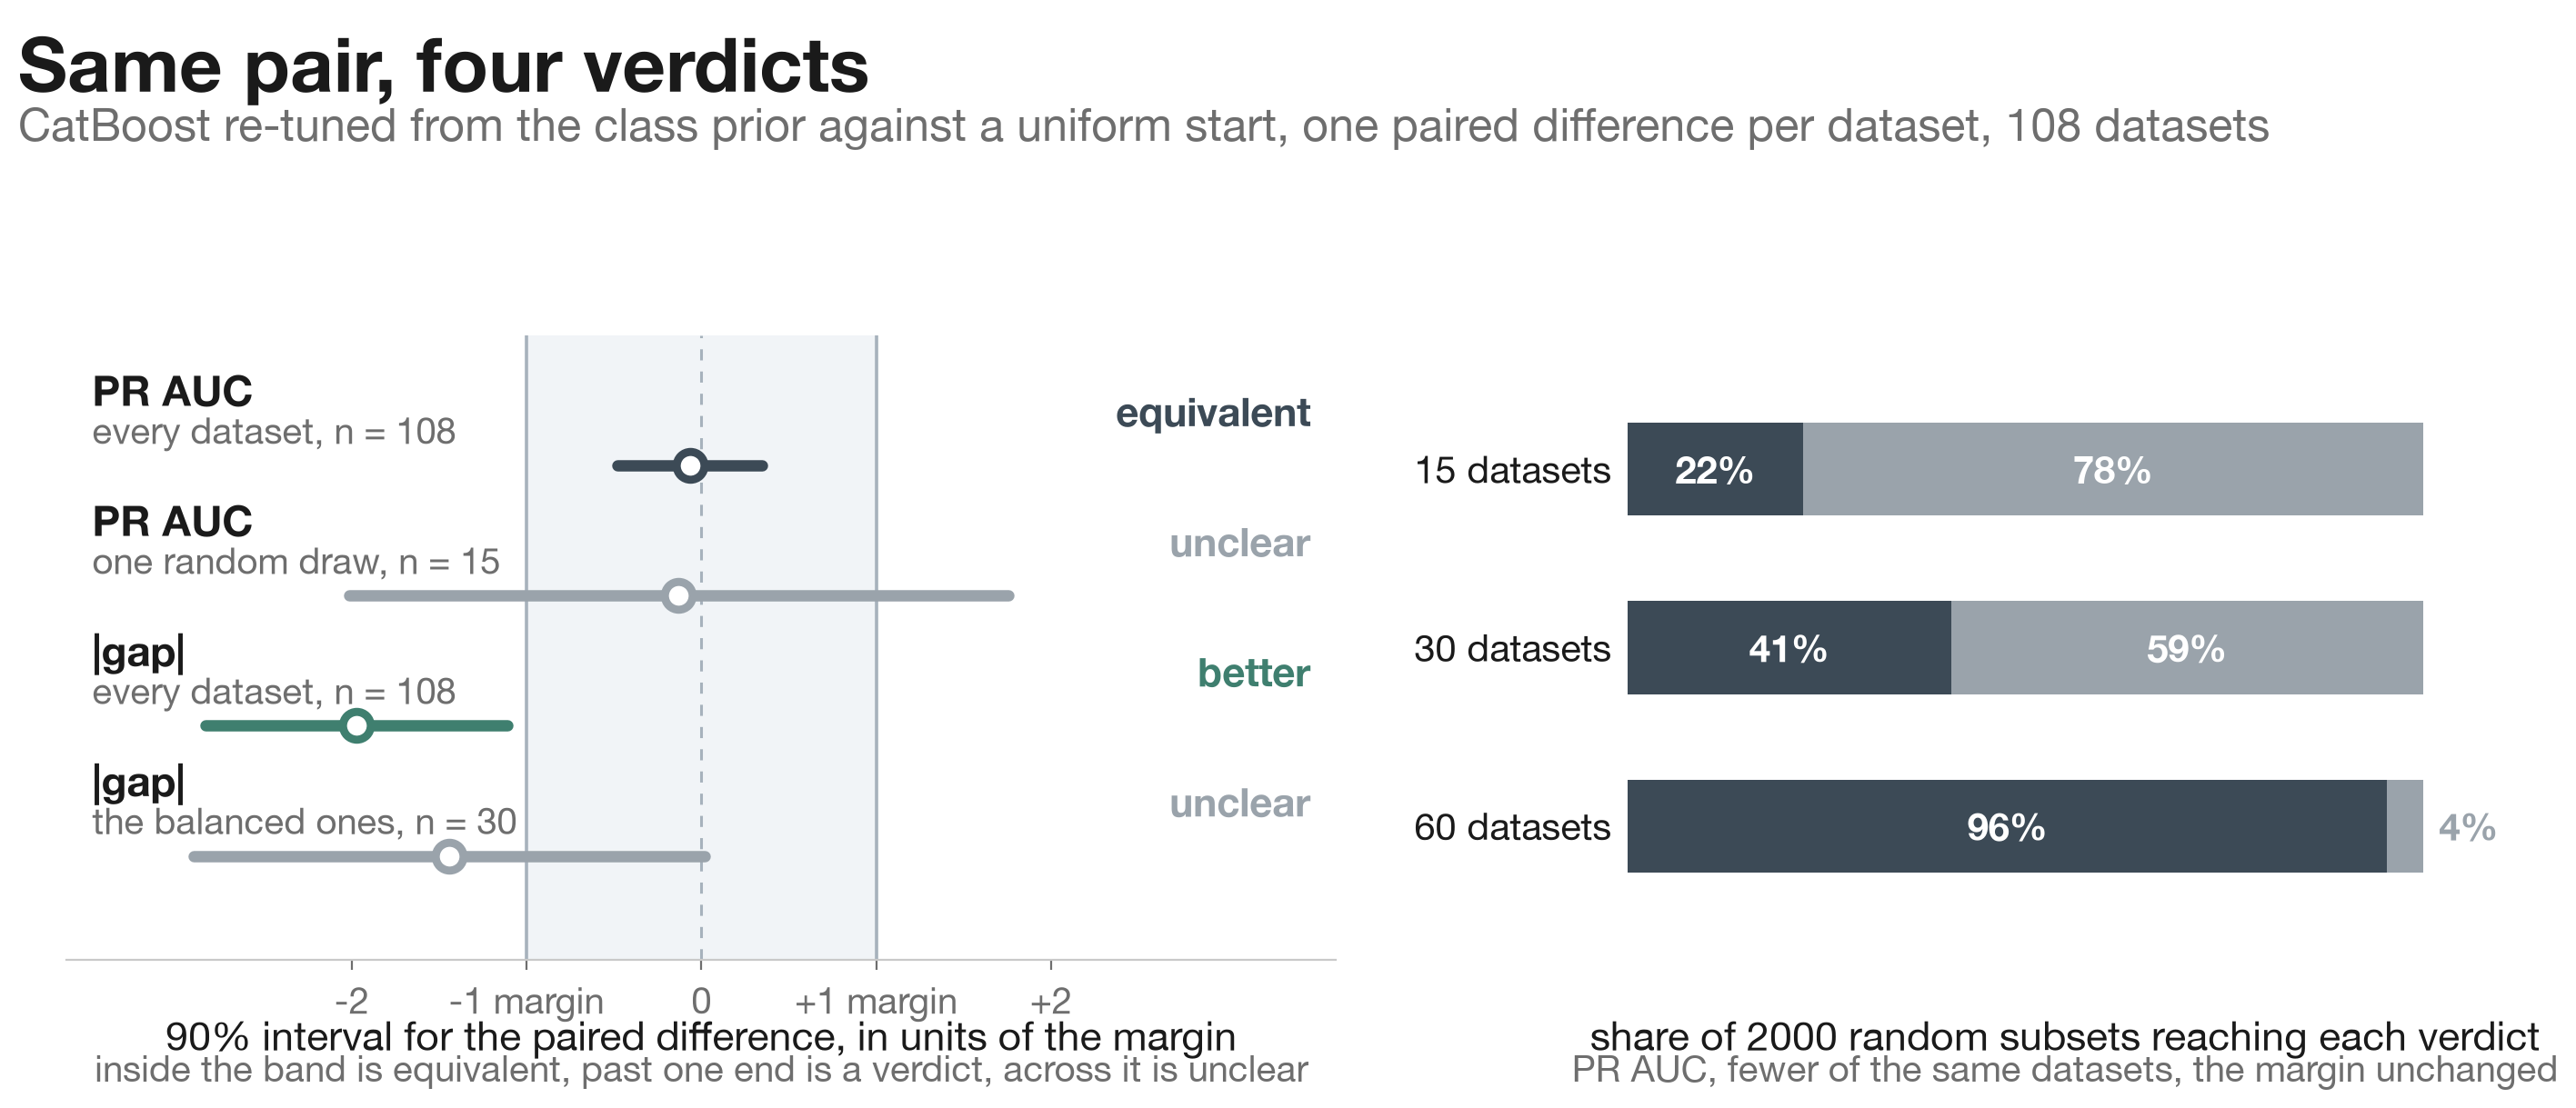

In [6]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"]
SLATE, ORANGE, GREY, TEAL = "#3C4A56", "#DE8A3F", "#9AA3AB", "#3F7F6F"
INK, MUTED, RULE, PANEL = "#1a1a1a", "#6e6e6e", "#A7B2BC", "#F1F4F7"
PAINT = {"equivalent": SLATE, "unclear": GREY, "better": TEAL, "worse": ORANGE}

fig, (ax, axr) = plt.subplots(1, 2, figsize=(14.6, 7.2), dpi=200,
                              gridspec_kw={"width_ratios": [1.45, 1]})
fig.patch.set_facecolor("white")


def caption(a, title, note):
    a.text(0.5, -0.145, title, transform=a.transAxes, fontsize=16, color=INK, ha="center")
    a.text(0.5, -0.195, note, transform=a.transAxes, fontsize=14.5, color=MUTED, ha="center")


# left: every interval in units of its own margin, so two metrics share one axis
ax.axvspan(-1, 1, color=PANEL, zorder=1)
for x in (-1, 1):
    ax.axvline(x, color=RULE, lw=1.3, zorder=2)
ax.axvline(0, color=RULE, lw=1.1, ls=(0, (4, 4)), zorder=2)
for y, r in enumerate(TAB.iloc[::-1].itertuples()):
    color = PAINT[r.verdict]
    ax.plot([r.lo/r.margin, r.hi/r.margin], [y, y], color=color, lw=4.5, solid_capstyle="round",
            zorder=4)
    ax.plot([r.mean/r.margin], [y], marker="o", ms=11, mfc="white", mec=color, mew=3.2, zorder=5)
    ax.text(0.02, y + 0.58, r.metric, transform=ax.get_yaxis_transform(), fontsize=16.5,
            fontweight="bold", color=INK, va="center")
    ax.text(0.02, y + 0.27, f"{r.rows}, n = {r.n}", transform=ax.get_yaxis_transform(),
            fontsize=14.5, color=MUTED, va="center")
    ax.text(0.98, y + 0.42, r.verdict, transform=ax.get_yaxis_transform(), fontsize=16,
            fontweight="bold", color=color, ha="right", va="center")
span = max(2.1, (TAB[["lo", "hi"]].abs().div(TAB.margin, axis=0)).max().max()*1.25)
ax.set_xlim(-span, span)
ax.set_ylim(-0.8, len(TAB) - 1 + 1.0)
ax.set_yticks([])
ax.set_xticks([-2, -1, 0, 1, 2], ["-2", "-1 margin", "0", "+1 margin", "+2"])
caption(ax, "90% interval for the paired difference, in units of the margin",
        "inside the band is equivalent, past one end is a verdict, across it is unclear")
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
ax.spines["bottom"].set_color("#c9c9c9")

# right: the same margin and metric, decided on fewer datasets
for y, (n, share) in enumerate(reversed(DRAWS.items())):
    left = 0.0
    for v, w in share.reindex(list(PAINT)).dropna().items():   # the verdicts allowed, in one order
        axr.barh(y, w, left=left, height=0.52, color=PAINT[v], zorder=3)
        inside = w >= 0.1                                # a sliver cannot hold its own label
        axr.text(left + w/2 if inside else 1.02, y, f"{w:.0%}",
                 color="white" if inside else PAINT[v], fontsize=15, fontweight="bold",
                 ha="center" if inside else "left", va="center", zorder=4)
        left += w
    axr.text(-0.02, y, f"{n} datasets", fontsize=15, color=INK, ha="right", va="center")
axr.set_xlim(0, 1.1)
axr.set_ylim(-0.75, len(DRAWS) - 0.25)
axr.axis("off")
caption(axr, f"share of {NDRAW} random subsets reaching each verdict",
        f"{PR_METRIC}, fewer of the same datasets, the margin unchanged")

ax.tick_params(labelsize=14.5, colors=MUTED, length=4)
fig.suptitle("Same pair, four verdicts", x=0.012, y=0.972, ha="left", fontsize=30,
             fontweight="bold", color=INK)
fig.text(0.012, 0.878, "CatBoost re-tuned from the class prior against a uniform start, one paired "
         f"difference per dataset, {NDATA} datasets", fontsize=18, color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0.075, 1, 0.84])
fig.savefig("model_comparison_decision.png", facecolor="white")
plt.show()

## How much of it is the margin

The margin is a product decision, so it is worth knowing how far it can move before the verdict does.
A verdict that survives only one value of the margin is a verdict about the margin.

In [7]:
print("the same data, the margin moved")
for metric, grid in (("PR AUC", (0.001, 0.002, 0.0025, 0.005, 0.01)),
                     ("|gap|", (0.005, 0.01, 0.0125, 0.02, 0.03))):
    lo, hi = t90(difference(D, metric))
    sign = SPEC[metric][1]
    print(f"  {metric:7s} interval [{lo:+.4f}, {hi:+.4f}]")
    print("          " + ",  ".join(f"{m:g} -> {verdict(lo, hi, m, sign)}" for m in grid))

the same data, the margin moved
  PR AUC  interval [-0.0024, +0.0017]
          0.001 -> unclear,  0.002 -> unclear,  0.0025 -> equivalent,  0.005 -> equivalent,  0.01 -> equivalent
  |gap|   interval [-0.0283, -0.0111]
          0.005 -> better,  0.01 -> better,  0.0125 -> unclear,  0.02 -> unclear,  0.03 -> equivalent


## And how much of it is counting one problem several times

The interval above treats every row as an independent draw. Several of these datasets are variants of
the same problem, cut at different numbers of classes or recorded in different sessions, and a model
that suits one tends to suit its siblings. Averaging each family to a single row is the cheap version
of taking that into account: it costs rows, which is the point.

The rule below only catches variants that differ by a trailing token, so it is a lower bound on the
clustering: pairs that differ in the middle of the name, such as the two ozone horizons or the two
wholesale targets, survive as separate rows. Going further by shared prefix is not safe, because some
prefixes mark provenance rather than a problem, and a collection like `statlog` would collapse into
one row although its members have nothing else in common.

In [8]:
# strip a trailing variant token: the class count, a session letter and number, a sensor index
FAMILY = (D.dataset.str.replace(r"[-_]?\d+class$", "", regex=True)
          .str.replace(r"-[a-z]*\d+[a-z]*$", "", regex=True))
members = D.dataset.groupby(FAMILY).apply(list)
print(f"{len(members)} families among {NDATA} datasets, the ones holding more than one:")
for name, group in members[members.str.len() > 1].items():
    print(f"  {name}: {', '.join(group)}")

print("per dataset, then one row per family")
for metric, (margin, sign) in SPEC.items():
    x = difference(D, metric)
    for s in (x, x.groupby(FAMILY).mean()):
        lo, hi = t90(s)
        print(f"  {metric:7s} {len(s):3d} rows  [{lo:+.4f}, {hi:+.4f}] -> {verdict(lo, hi, margin, sign)}")

95 families among 108 datasets, the ones holding more than one:
  abalone: abalone-3class, abalone-7class
  robot-failure: robot-failure-lp1, robot-failure-lp4, robot-failure-lp5
  robot-nav-sensor-readings: robot-nav-sensor-readings-2, robot-nav-sensor-readings-24, robot-nav-sensor-readings-4
  vertebra-column: vertebra-column-2c, vertebra-column-3c
  volcanoes: volcanoes-a1, volcanoes-a2, volcanoes-a4, volcanoes-b1, volcanoes-b2, volcanoes-c1, volcanoes-d1, volcanoes-d2
per dataset, then one row per family
  PR AUC  108 rows  [-0.0024, +0.0017] -> equivalent
  PR AUC   95 rows  [-0.0026, +0.0021] -> equivalent
  |gap|   108 rows  [-0.0283, -0.0111] -> better
  |gap|    95 rows  [-0.0258, -0.0086] -> unclear


## What this notebook measured

The quantity decides the answer before any test does. On the balanced datasets the signed gap and the
absolute gap, computed from the same two columns of the same table, return p-values on opposite sides
of the usual threshold. Neither is wrong; they are answers to different questions, and only one of
them is the question a calibration claim asks.

With the margin fixed first, the four readings split three ways. The accuracy metric on every dataset
is equivalent, with an interval comfortably inside the band: the change does not cost accuracy, which
is a conclusion a p-value alone cannot deliver, because its silence there means only that nothing was
detected. The same metric on fifteen datasets is unclear, with an interval about twice the width of
the band. The calibration metric on every dataset lands past the band, and on the balanced subset it
straddles it.

Each of the three remaining cells moves a verdict without touching the data. Random subsets show the
fifteen-dataset reading is typical rather than unlucky, and the resampled version of that question,
which is the one that speaks to sample size, puts the number of datasets a comparison like this needs
well above what it is usually run on. Moving the margin inside the range a product argument could
plausibly defend turns the calibration verdict from a win into unclear, and shrinking it to well under
the stated value does the same to the accuracy verdict: both words are statements about a margin, not
only about the data. Collapsing each family of sibling datasets to one row flips the calibration
verdict as well, and the printed intervals show how: the width barely moves, the mean does.

So what is reportable is the verdict together with what it rests on. At the margins fixed here,
accuracy is equivalent, and calibration is an improvement that survives only while the margin stays
at or under the value set for it and sibling datasets are counted one by one. Both of those are
defensible choices rather than facts about the models, which is the point: the word to report is the
one that survives the choices you are willing to defend, and the margin has to be written down before
the interval is read.

One caveat on the inputs rather than the method: the table is published rounded, so a p-value here
can differ in its second digit from one computed on the unrounded values.